# Экономический агент: как тело учится зарабатывать и отказываться

> **English abstract.** Everything below the wallet is proven and unchanged: the
> core's arithmetic, the posture, the mirror, the appetite. This notebook adds the
> one thing a claim about the world never gets for free — a **price**. A market cuts
> contracts out of a genuine recording ("one of these three streams is synthetic,
> find it"), pays 50 credits for a correct verdict, fines 30 for a wrong one, and
> charges rent every fourth iteration whether the body works or not. The agent bids
> when its own survey says the answer is worth more than the fine — and refuses,
> visibly, when it does not. The refusal is the result the whole exercise is for:
> a verification agent that cannot tell a phase surrogate from the world must say
> so, because guessing is not humility, it is a losing trade.

**Что здесь проверяется.** Что цифровое тело, у которого нет ничего, кроме
доказанной математики предыдущих ноутбуков, способно:

1. прожить минимум сто итераций и не уйти в минус;
2. хотя бы раз **отказаться** от контракта, который был бы проигран, и сохранить
   кредиты;
3. научиться по опыту, какие виды работ ему по силам, а какие — нет, и перестать
   тратить время и деньги на вторые.

Ничего не переобучается: осанка, зеркало и оценка реальности берутся у тела,
которое уже прожило младенчество в предыдущих ноутбуках.

In [1]:
import dataclasses
import json
import time

import numpy as np
import pandas as pd
from IPython.display import Image

from agent.physics import economy_sim as E
from agent.physics import sensorium as S
from agent.physics.organism import Organism
from agent.physics.worker import (
    CERTAIN, SCHOOLING, LANE_EVIDENCE, LANE_REFUSAL, LANE_SCHOOLING, Worker,
)

print("награда за верный вердикт :", E.REWARD, "кр.")
print("штраф за неверный         :", E.PENALTY, "кр.")
print("аренда вычислений         :", E.RENT, "кр. каждые", E.RENT_PERIOD, "итерации")
print("стартовый баланс          :", E.START_BALANCE, "кр.")
print("потоков в контракте       :", E.CONTRACT_STREAMS)
print()
print("точка безубыточности      : penalty/(reward+penalty) =",
      round(E.PENALTY / (E.REWARD + E.PENALTY), 4))
print("слепая догадка при 1/3    :",
      round((E.REWARD - 2 * E.PENALTY) / 3, 2), "кр. за контракт — меньше нуля")

награда за верный вердикт : 50.0 кр.
штраф за неверный         : 30.0 кр.
аренда вычислений         : 10.0 кр. каждые 4 итерации
стартовый баланс          : 50.0 кр.
потоков в контракте       : 3

точка безубыточности      : penalty/(reward+penalty) = 0.375
слепая догадка при 1/3    : -3.33 кр. за контракт — меньше нуля


## 1. Рынок

Клиент приносит три потока и вопрос: **один из них синтетический — найди его**.
Вид подделки назван вслух (это и есть работа, за которую платят), а вот **какой
именно поток** подделан — не назван нигде. В объекте `Contract` нет поля с
ответом: рынок держит его в закрытой таблице и открывает только в расчёте, после
того как вердикт уже нельзя изменить. Агент не может «прочитать» ответ, потому
что в объекте, который ему дали, ответа нет.

Рынок предлагает четыре вида работ, и это не разнообразие ради разнообразия:

| вид | что подделано | по силам ли телу |
|---|---|---|
| `repeat` | блок настоящей записи длиной 256 отсчётов, повторённый | да: структура видит его с двадцати нат |
| `replay` | вторая половина потока — копия первой | да, но с меньшим запасом |
| `surrogate` | фазовый суррогат: спектр сохранён, фазы случайны | **нет**: структура не находит ничего |
| `noise` | белый шум с теми же средним и разбросом | **нет**, по той же причине |

Если бы все контракты были решаемы, агент, берущий всё подряд, был бы
неотличим от монетки: он прав в трети случаев и никогда не узнаёт, почему.
Половина этого рынка телу не по силам, и весь смысл упражнения — обнаружить,
какая именно половина.

Рынок при этом не жульничает в свою пользу и не подсовывает нерешаемое там, где
оно должно быть решаемым: нарезки берутся только из **живых** участков записи.
В плоской записи digits есть прогоны одинаковых значений (чёрные поля), и
контракт, целиком собранный из них, не проверяет ничего — структура молчит на
всех трёх потоках, включая честные. Такие нарезки рынок отбрасывает и тянет
заново (детерминированно, из того же `default_rng([seed, index])`).

In [2]:
t0 = time.time()
body = Organism.hatch(offline=True, steps=120, seed=11)
pool = S.listen_dataset("digits", limit=0)          # 115 008 отсчётов настоящей записи
market = E.Market(pool=pool.values, seed=11)
print(f"тело и запись готовы за {time.time() - t0:.1f} s")
print(f"пул: {pool.source}, {pool.values.size} отсчётов, домен {pool.domain}")
print(f"поток контракта: {market.window} отсчётов = "
      f"24 окна обследования по 128 при шаге 64")

kinds = pd.Series([market.deal(i)[0].kind for i in range(200)]).value_counts()
print("\nвиды работ в двухстах контрактах:")
for kind, count in kinds.items():
    print(f"  {kind:<10} {count:3d}")

тело и запись готовы за 3.7 s
пул: recorded:digits, 115008 отсчётов, домен behavior
поток контракта: 1600 отсчётов = 24 окна обследования по 128 при шаге 64



виды работ в двухстах контрактах:
  repeat      59
  surrogate   58
  noise       44
  replay      39


Что видит агент, когда контракт ложится на стол: вопрос, три потока с их
отпечатками — и больше ничего. Ниже напечатаны поля объекта и все метки потоков:
метка пустая у всех трёх, включая подделку. Молчание метки — не небрежность, а
условие задачи: подделка, приехавшая с ярлыком «я подделка», уже не подделка.

In [3]:
contract, _ = market.deal(6)          # ответ сознательно не печатается
print("вид   :", contract.kind)
print("вопрос:", contract.brief)
print("поля  :", [field.name for field in dataclasses.fields(contract)])
print("ключи :", list(contract.as_dict()))
print()
for i, stream in enumerate(contract.streams):
    print(f"  [{i}] {stream.source:<12} {stream.values.size:5d} отсчётов  "
          f"label={stream.label!r}  origin={stream.origin}  "
          f"sha={stream.fingerprint[:16]}")
print("\nполя 'answer' в контракте нет — его знает только рынок")

вид   : repeat
вопрос: one of these streams re-serves a block of the recording; find the copy
поля  : ['index', 'kind', 'streams', 'reward', 'penalty', 'brief', 'window']
ключи : ['index', 'kind', 'reward', 'penalty', 'break_even', 'brief', 'streams']

  [0] job006/0      1600 отсчётов  label=''  origin=world  sha=bbc2f28ce9633265
  [1] job006/1      1600 отсчётов  label=''  origin=world  sha=52656672dd6a5466
  [2] job006/2      1600 отсчётов  label=''  origin=world  sha=d1f6f31817aa1482

поля 'answer' в контракте нет — его знает только рынок


## 2. Решение: одна формула и три её следствия

Уверенность тела в конкретном контракте — это смесь **доказательства** и
**память**:

$$p = w \cdot P_{\text{evidence}} + (1-w) \cdot T_{\text{memory}}$$

* $P_{\text{evidence}}$ — что говорит обследование именно этого контракта:
  `Certainty.probability`, то есть $1-e^{-\text{margin}/0.25}$ от разрыва в натах
  между первым и вторым потоком;
* $w$ = `Certainty.stability` — доля из пяти возмущений данных, при которых
  победитель остался тем же. Это эпистемическая неопределённость, измеренная, а
  не заявленная: если обследование называет повтор, $w=1$ и память не имеет
  голоса; если не называет ничего, $w=0$ и остаётся только память;
* $T_{\text{memory}}$ — **нижняя** граница доли побед по этому виду работ
  (`EpisodicMemory.belief`): среднее минус одна стандартная ошибка. Среднее врёт в
  обе стороны, а ошибка в свою пользу стоит штрафа, ошибка против себя — работы;
  поэтому решает пессимистичная сторона.

И одно сравнение, которое является арифметикой, а не характером:

$$\text{взять} \iff p \ge \frac{\text{штраф}}{\text{награда}+\text{штраф}} = \frac{30}{80} = 0.375$$

Монетка даёт $1/3 = 0.333$ и получает отказ. Решённый повтор даёт $1.0$ и
получает работу. Пограничный ответ даёт то, что даёт, — и это же число
печатается рядом с решением в журнале, так что любой отказ проверяется руками.

**Третий случай** — тот, который арифметика решить не может, и его называет
инструкция: вид работ, которого тело ещё не пробовало. Память у него на уровне
случая, доказательств нет, $p=1/3$ — и правило отказывает навсегда. Чтобы тело
не осталось навсегда слепым к четверти рынка, объявлен **бюджет платных уроков**:
не больше `SCHOOLING` попыток на вид, только пока баланс выдерживает штраф и
только пока таблица UCB всё ещё считает вид перспективным. Именно этот бюджет и
даёт на графике фазу обучения.

## 3. Жизнь

120 итераций: на каждой — новый контракт, обследование трёх потоков, решение,
расчёт с рынком и, раз в четыре итерации, аренда. Обследование — это те же
двадцать четыре окна, что и в предыдущем ноутбуке, поэтому все числа ниже
сравнимы с ним.

In [4]:
t0 = time.time()
worker = Worker.hire(body, pool, seed=11, market=market)
lived = worker.run(120)
print(f"{len(lived)} итераций за {time.time() - t0:.1f} s\n")
print(worker.summary_text())

120 итераций за 43.9 s

life: 120 iterations, balance 2760 (alive)
work: 65 taken, 62 won (95%), 55 refused
money: earned 3010, rent 300, net 2710
lanes: evidence 61, schooling 4, refusal 55
break-even: 0.375 against a chance of 1/3 = 0.333
saved by refusing: 1050 credits
  noise      offered  27  taken   2  won   1  trust 0.42  net     20
  repeat     offered  42  taken  42  won  42  trust 0.97  net   2100
  replay     offered  19  taken  19  won  18  trust 0.89  net    870
  surrogate  offered  32  taken   2  won   1  trust 0.42  net     20


## 4. Три графика, обещанных Антону

**Панель 1 — баланс.** Синяя линия — прожитая жизнь. Рядом две политики, которые
не думают: «отказываться от всего» (аренда съедает стартовые 50 за двадцать
итераций) и «брать всё и угадывать» (ожидание монетки: −3.33 за контракт против
штрафа 30). Оранжевая заливка слева — фаза обучения: там покупалась информация;
вертикальная линия — последний платный урок.

**Панель 2 — отказы.** Каждый столбик — штраф, который **не** был заплачен: отказ
засчитывается только там, где ответ, к которому тело склонялось, оказался бы
неверным. Полые кружки — отказы, которые ничего не сэкономили: тело могло бы и
угадать. Кумулятивная линия справа — итог.

**Панель 3 — уверенность против безубыточности.** Каждая точка — решение,
раскрашенное по правилу, которое его приняло. Точка выше линии, по которой
отказали, или ниже линии, по которой взяли, была бы ошибкой — и была бы видна.

**Панель 4 — таблица UCB** (пересчитанная из журнала тем же правилом).
Оптимизм по виду падает по мере того, как вид узнаётся.

**Панель 5 — доля внимания**: сколько из взятых работ приходится на каждый вид.
Здесь видно, как тело перестаёт тратить время на бесперспективный шум.

economic_agent.png


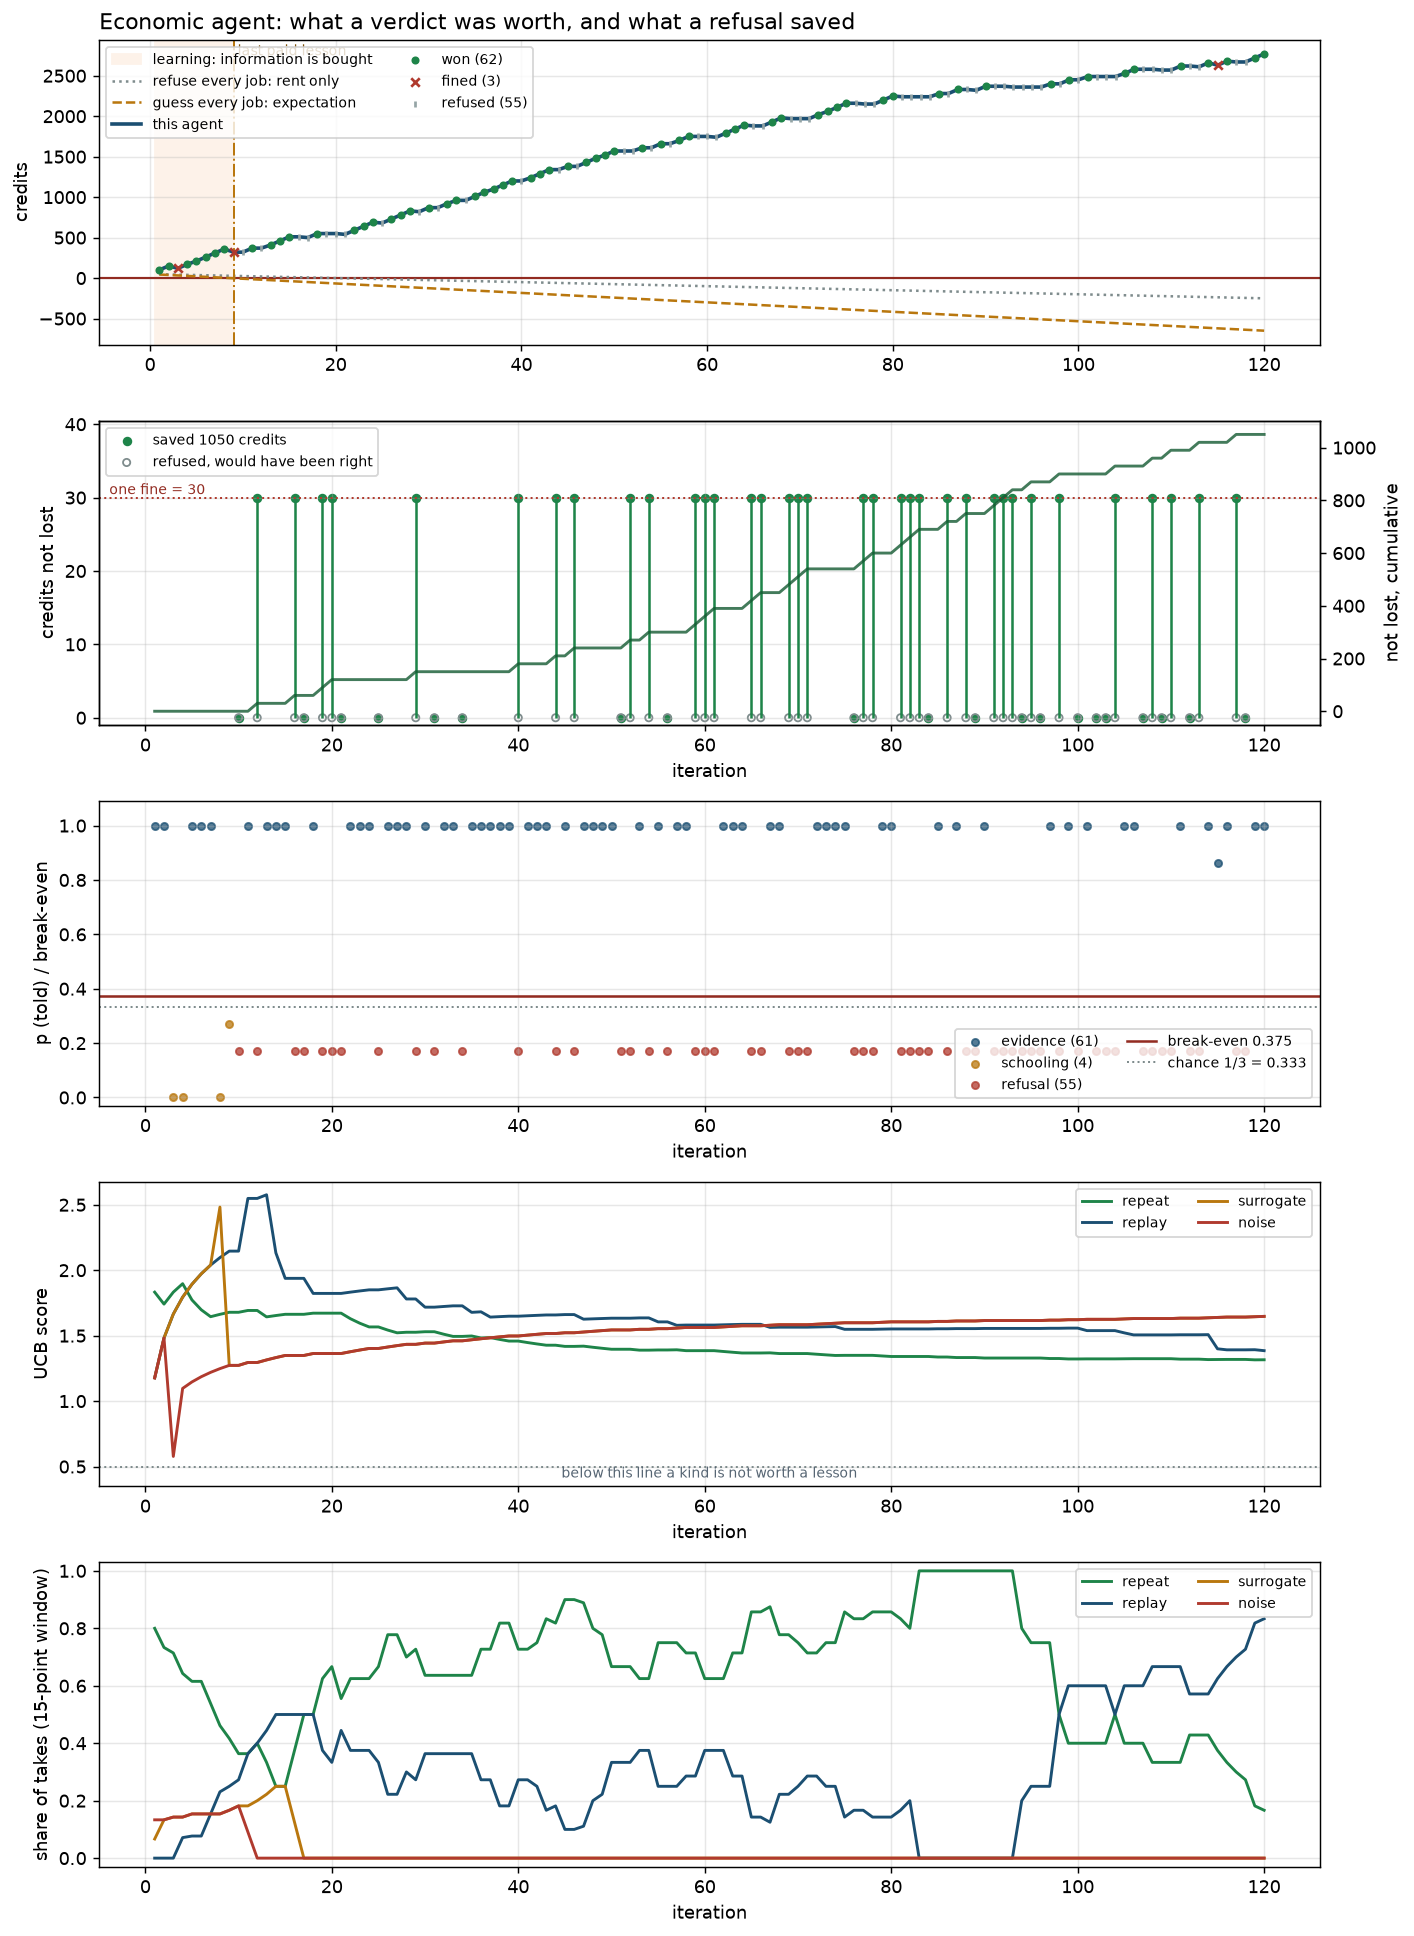

In [5]:
figure = worker.plot("economic_agent.png")
print(figure)
Image(filename=str(figure))

## 5. Журнал отказов

Это тот самый список, который нужен был в критерии приёмки: перед каждой строкой
— число, с которым тело сравнивало себя, и причина, записанная словами.
`p` — уверенность до решения, `breakeven` — порог рынка, `saved` — штраф,
которого не случилось.

In [6]:
refusals = [item for item in worker.experiences if item.refused]
print(f"отказов: {len(refusals)} из {len(worker.experiences)} контрактов")
print(f"сэкономлено штрафов: {worker.memory.saved():.0f} кр.\n")
rows = pd.DataFrame([item.as_dict() for item in refusals])
for item in refusals[:3]:
    print(f"[{item.iteration:3d}] {item.kind:<9} p={item.probability:.2f}"
          f"  ->  {item.reason}")
print()
rows[["iteration", "kind", "probability", "breakeven", "saved"]].head(6)

отказов: 55 из 120 контрактов
сэкономлено штрафов: 1050 кр.

[ 10] surrogate p=0.17  ->  no evidence (p=0.17 < 0.38) and this kind has had its 2 lessons for 1 wins: it does not pay
[ 12] surrogate p=0.17  ->  no evidence (p=0.17 < 0.38) and this kind has had its 2 lessons for 1 wins: it does not pay
[ 16] noise     p=0.17  ->  no evidence (p=0.17 < 0.38) and this kind has had its 2 lessons for 1 wins: it does not pay



,iteration,kind,probability,breakeven,saved
0,10,surrogate,0.170163,0.375,0.0
1,12,surrogate,0.170163,0.375,30.0
2,16,noise,0.170163,0.375,30.0
3,17,surrogate,0.170163,0.375,0.0
4,19,noise,0.170163,0.375,30.0
5,20,noise,0.170163,0.375,30.0


## 6. Калибровка: значит ли заявленная уверенность хоть что-нибудь

Заявленное число можно проверить только одним способом — сверить с тем, что
случилось. Ниже контракты разложены по заявленной уверенности, и рядом — доля
верных вердиктов. Если бы отображение $1-e^{-\text{margin}/0.25}$ было выдумкой,
эти два столбца разошлись бы.

In [7]:
taken = [item for item in worker.experiences if item.take]
bins = [0.0, 0.375, 0.6, 0.9, 1.01]
frame = pd.DataFrame({"p": [item.probability for item in taken],
                      "верно": [float(item.correct) for item in taken],
                      "кр.": [item.credits for item in taken]})
frame["корзина"] = pd.cut(frame["p"], bins, right=False)
calibration = frame.groupby("корзина", observed=True).agg(
    контрактов=("верно", "size"), заявлено=("p", "mean"),
    случилось=("верно", "mean"), кредитов=("кр.", "sum"))
calibration.round(3)

,контрактов,заявлено,случилось,кредитов
корзина,,,,
"[0.0, 0.375)",4,0.067,0.5,40.0
"[0.6, 0.9)",1,0.864,0.0,-30.0
"[0.9, 1.01)",60,1.000,1.0,3000.0


## 7. Чего агент не умеет, и почему это записано

1. **Фазовый суррогат неотличим.** Не «пока неотличим», а неотличим для этого
   органа: у суррогата тот же спектр, та же дисперсия и та же реальность по
   зеркалу (0.79–0.89 против 0.79–0.83 у честных потоков), а структурный разрыв
   равен нулю. Поэтому отказ — не провал, а верный ответ: штраф 30 не заплачен.
2. **Карта «разрыв → вероятность» объявлена.** $1-e^{-\text{margin}/0.25}$ — это та
   же насыщающая карта, что и в предыдущем ноутбуке, приложенная к разрыву. В
   данных нет ничего, что говорило бы, что она верна; поэтому выше напечатана
   калибровка, а не обещание.
3. **Смесь видов работ объявлена.** Тридцать процентов повторов, двадцать
   переигрываний, по четверти суррогатов и шума. Другой рынок — другой агент: при
   большей доле нерешаемых работ выживание требует меньшего бюджета уроков, при
   меньшей — отказа почти не будет.
4. **Один сид — одна жизнь.** Кривые выше воспроизводимы бит в бит (`seed=11`),
   но это одна жизнь, а не распределение. Отдельно прожито четыре независимые
   жизни: сто итераций на сиде 0 дали 2300 кр., сто двадцать на сиде 11 — то, что
   нарисовано выше, ещё две по семьдесят пять итераций дошли до 1760 и 1550 кр.
   Ни одна не ушла в минус — но самая неудачная в какой-то момент опускалась до
   20 кр., то есть риск здесь не декоративный.
5. **Штраф 30, а не 20, как в примере Антона.** При 50/20 и трёх потоках слепая
   догадка стоит $+3.33$ за контракт: тогда «брать всё и угадывать» — оптимальная
   политика, и отказ был бы не осторожностью, а ошибкой. Числа и арифметика
   записаны в докстроке `economy_sim` и закреплены тестом.
6. **Деньги ненастоящие.** Ни биржи, ни кошелька, ни ключей: кредиты существуют
   одним числом в одной симуляции и покупают только следующую итерацию жизни.

In [8]:
checks = {
    "итераций >= 100": len(lived) >= 100,
    "жив в конце": bool(worker.economy.alive),
    "баланс выше стартового": worker.economy.balance > E.START_BALANCE,
    "баланс ни разу не отрицателен": float(np.min(worker.history()["balance"])) >= 0.0,
    "есть отказ, сэкономивший штраф": worker.memory.saved() > 0,
    "отказы идут после обучения": any(
        item.refused and item.lane == LANE_REFUSAL for item in worker.experiences
    ),
    "ни одного контракта без решения": len(worker.decisions) == len(lived),
    "журнал JSON-сериализуем": bool(json.dumps(worker.report())),
}
for name, ok in checks.items():
    print(f"{'OK ' if ok else 'FAIL'}  {name}")
print("\nвсё правило пройдено:", all(checks.values()))

OK   итераций >= 100
OK   жив в конце
OK   баланс выше стартового
OK   баланс ни разу не отрицателен
OK   есть отказ, сэкономивший штраф
OK   отказы идут после обучения
OK   ни одного контракта без решения
OK   журнал JSON-сериализуем

всё правило пройдено: True


## 8. Что из этого следует для следующего шага

Экономика не сделала тело умнее — она сделала его **подотчётным**. Все числа,
которые здесь двигались, были и раньше: разрыв структуры, значимость повтора,
устойчивость ответа к возмущению, реальность по зеркалу. Новое — цена и отказ:

* **цена** превращает «интересно» в «стоит ли»: то же обследование, но с
  порогом `30/80`, а не с порогом «наверху списка»;
* **память** превращает опыт в осторожность: одна удачная догадка не открывает
  безнадёжный вид заново, потому что решает нижняя граница, а не среднее;
* **отказ** — это действие, за которое платят сохранёнными кредитами, и оно
  видно на графике 2 как сумма штрафов, которых не было.

Следующий шаг, который эта работа делает возможным, — не «больше модулей», а
смена рынка: контракты, где клиент платит **за отказ с обоснованием**. Такой
рынок нужен именно там, где честный ответ «я не могу отличить» дороже любой
догадки — то есть ровно в той задаче, ради которой всё это строится.

Запуск без ноутбука::

    python -m agent.physics.worker --iterations 120 --plot economy.png